# Import Pandas

In [1]:
import pandas as pd

# Import Matplotlib

In [2]:
import matplotlib.pyplot as plt

# Import Seaborn

In [3]:
import seaborn as sns

# Load the cleaned dataset

In [4]:
df = pd.read_csv(r"D:\DataScience_with_Python\Week5\titanic_analysis_ready.csv")

# Understanding the dataset

## Displaying the first five rows

In [5]:
df.head()

,survived,pclass,name,sex,age,sibsp,parch,fare,embarked,classname,familysize
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S,Third Class,2
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C,First Class,2
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S,Third Class,1
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S,First Class,2
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S,Third Class,1


This shows the first five passengers.

## Checking rows and columns

In [6]:
df.shape

(891, 11)

## Checking column names

In [7]:
df.columns

Index(['survived', 'pclass', 'name', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'classname', 'familysize'],
      dtype='object')

This shows the available features such as age, sex, fare, survived, and passenger class.

## Checking dataset information

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   survived    891 non-null    int64  
 1   pclass      891 non-null    int64  
 2   name        891 non-null    object 
 3   sex         891 non-null    object 
 4   age         891 non-null    float64
 5   sibsp       891 non-null    int64  
 6   parch       891 non-null    int64  
 7   fare        891 non-null    float64
 8   embarked    891 non-null    object 
 9   classname   891 non-null    object 
 10  familysize  891 non-null    int64  
dtypes: float64(2), int64(5), object(4)
memory usage: 76.7+ KB


This shows column types and non-null counts.

## Checking missing values

In [9]:
df.isnull().sum()

survived      0
pclass        0
name          0
sex           0
age           0
sibsp         0
parch         0
fare          0
embarked      0
classname     0
familysize    0
dtype: int64

Zero missing values in every column, because the dataset was cleaned in Week 3.

## Checking duplicates

In [10]:
df.duplicated().sum()

np.int64(0)

## Displaying descriptive statistics

In [11]:
df.describe()

,survived,pclass,age,sibsp,parch,fare,familysize
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208,1.904602
std,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429,1.613459
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400,1.000000
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200,1.000000
75%,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000,2.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,11.000000


This shows the mean, minimum, maximum, standard deviation, and quartiles of numerical features.

# Creating visualizations

## Histogram — Age distribution

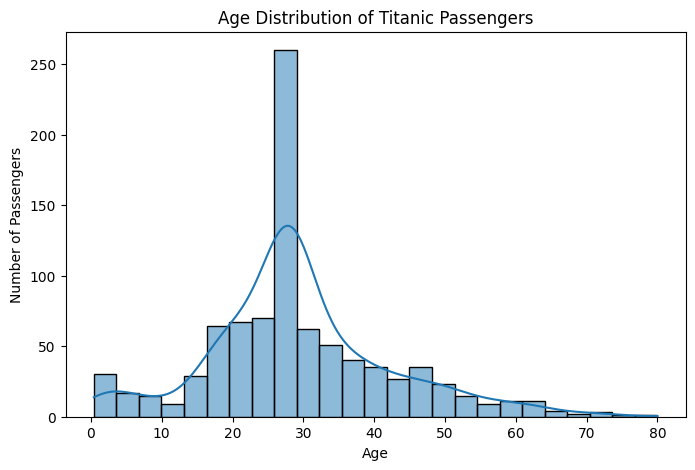

In [12]:
# Understanding how passenger ages are distributed.
plt.figure(figsize=(8, 5))

sns.histplot(df["age"], bins=25, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

The histogram shows how frequently different passenger ages appear.
The high count around age 28 is partly due to replacing missing ages with the median in Week 3.

## Box plot — Ticket fare by class

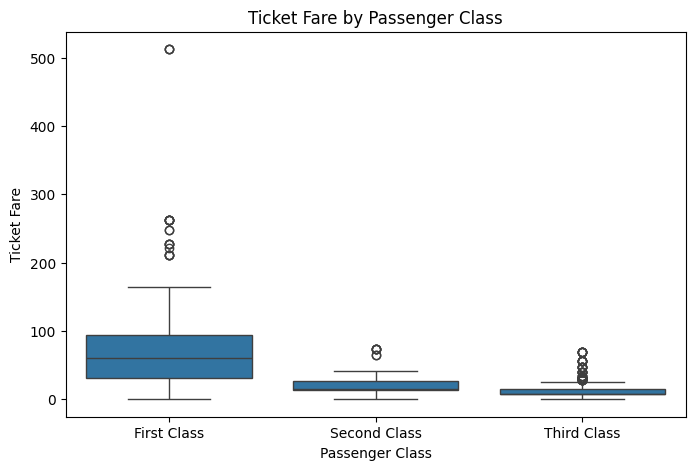

In [13]:
# Comparing ticket fares between passenger classes and identify outliers.
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="classname",
    y="fare",
    order=["First Class", "Second Class", "Third Class"]
)

plt.title("Ticket Fare by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Ticket Fare")

plt.show()

The box plot shows the spread of ticket prices. Dots beyond the whiskers indicate potential outliers;
Outliers are data values that are unusually high or unusually low compared to most other values in a dataset.

## Scatter plot — Age vs. ticket fare

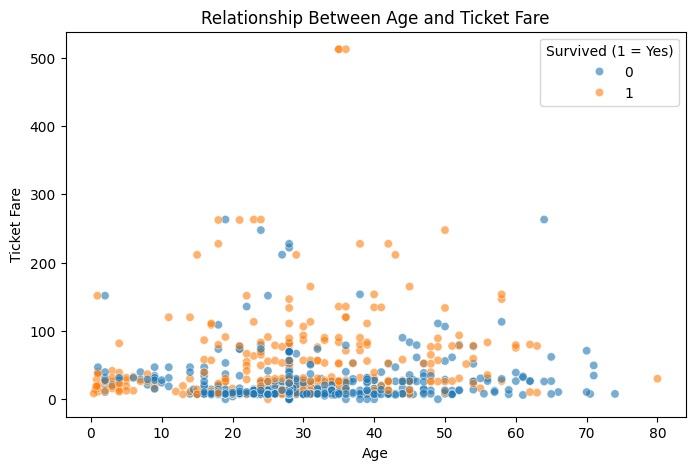

In [14]:
# Exploring the relationship between passenger age and ticket fare.
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="fare",
    hue="survived",
    alpha=0.6
)

plt.title("Relationship Between Age and Ticket Fare")
plt.xlabel("Age")
plt.ylabel("Ticket Fare")
plt.legend(title="Survived (1 = Yes)")

plt.show()

Each dot represents a passenger. The chart helps us observe whether age and fare appear related and where survivors and non-survivors occur.

## Calculating correlations

In [15]:
correlation = df[["survived", "pclass", "age", "sibsp", "parch", "fare", "familysize"]].corr()
correlation

,survived,pclass,age,sibsp,parch,fare,familysize
survived,1.000000,-0.338481,-0.064910,-0.035322,0.081629,0.257307,0.016639
pclass,-0.338481,1.000000,-0.339898,0.083081,0.018443,-0.549500,0.065997
age,-0.064910,-0.339898,1.000000,-0.233296,-0.172482,0.096688,-0.245619
sibsp,-0.035322,0.083081,-0.233296,1.000000,0.414838,0.159651,0.890712
parch,0.081629,0.018443,-0.172482,0.414838,1.000000,0.216225,0.783111
fare,0.257307,-0.549500,0.096688,0.159651,0.216225,1.000000,0.217138
familysize,0.016639,0.065997,-0.245619,0.890712,0.783111,0.217138,1.000000


This calculates correlation coefficients between numerical features.

## Heatmap — Correlations

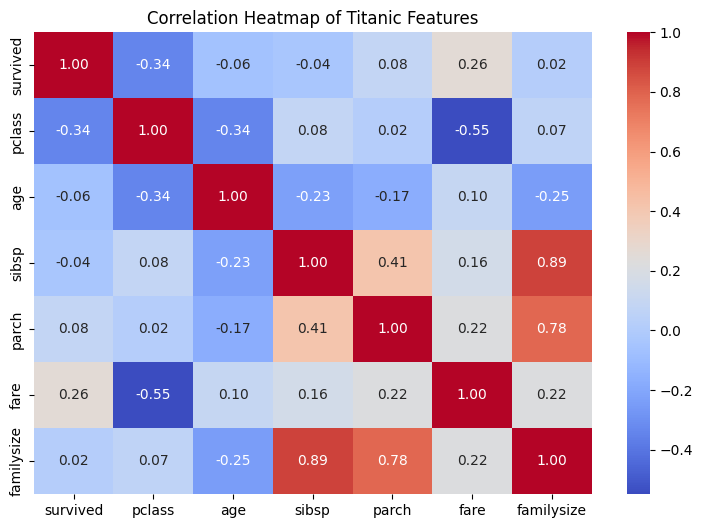

In [16]:
# Visualizing relationships between numerical features.
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Titanic Features")

plt.show()

Positive correlations mean two values tend to increase together. 
Negative correlations mean one tends to decrease as the other increases. Correlation does not prove causation.

# Analyzing survival patterns

## Calculating the overall survival rate

In [17]:
overall_survival = df["survived"].mean() * 100

print(f"Overall survival rate: {overall_survival:.2f}%")

Overall survival rate: 38.38%


## Calculating survival rate by gender

In [18]:
gender_survival = df.groupby("sex")["survived"].mean() * 100
gender_survival

sex
female    74.203822
male      18.890815
Name: survived, dtype: float64

## Bar chart — Survival rate by gender

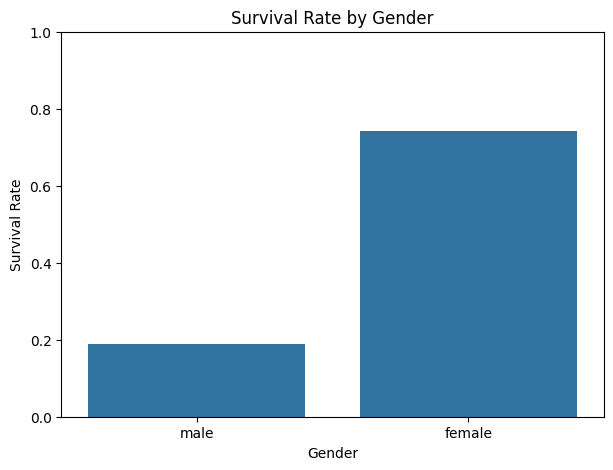

In [19]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="sex",
    y="survived",
    errorbar=None
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)

plt.show()

The y-axis shows survival as a proportion, from 0 to 1. Multiply by 100 to interpret it as a percentage.

## Calculating survival rate by class

In [20]:
class_survival = df.groupby("classname")["survived"].mean() * 100
class_survival

classname
First Class     62.962963
Second Class    47.282609
Third Class     24.236253
Name: survived, dtype: float64

## Bar chart — Survival rate by class

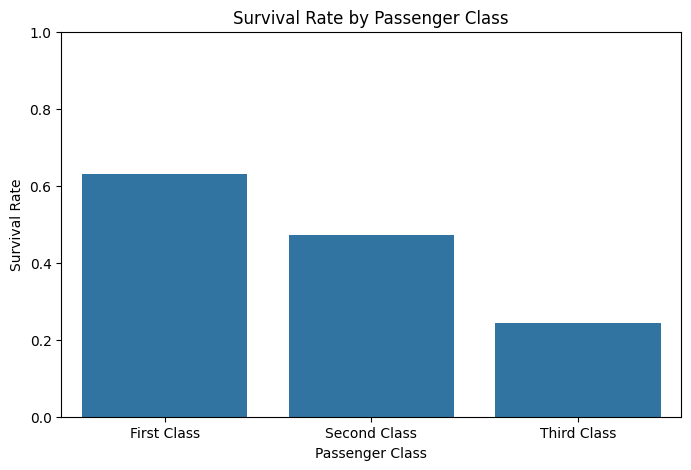

In [21]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="classname",
    y="survived",
    order=["First Class", "Second Class", "Third Class"],
    errorbar=None
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)

plt.show()

## Creating family-size categories

In [22]:
# We group passengers into three categories to make the family-size comparison to understand easily.
df["family_group"] = pd.cut(
    df["familysize"],
    bins=[0, 1, 4, 100],
    labels=["Alone", "Small Family", "Large Family"]
)

## Calculating survival rate by family size

In [23]:
family_survival = (df.groupby("family_group", observed=True)["survived"].mean() * 100)
family_survival

family_group
Alone           30.353818
Small Family    57.876712
Large Family    16.129032
Name: survived, dtype: float64

Here, small families have 2–4 people, and large families have 5 or more.

## Bar chart — Survival rate by family size

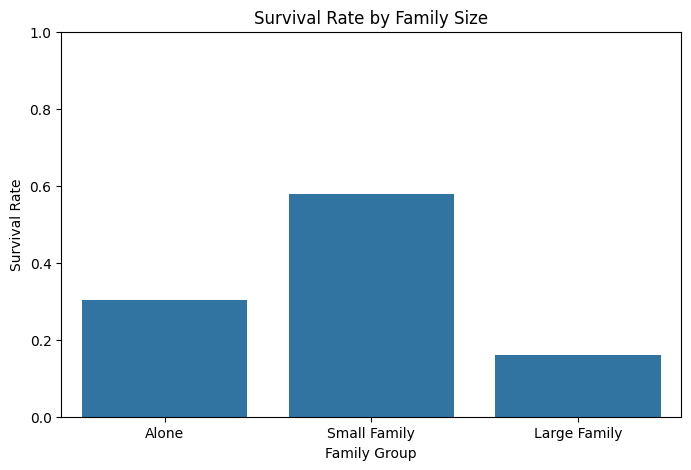

In [24]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="family_group",
    y="survived",
    errorbar=None
)

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Group")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)

plt.show()

## Analyzing ticket fares

In [25]:
df["fare"].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: fare, dtype: float64

This shows the average, median, and highest ticket fares.

# Five Key Insights from Exploratory Data Analysis
Insight 1: Female passengers had a higher survival rate.

The analysis shows that approximately 74.20% of female passengers survived, compared with only 18.89% of male passengers. This indicates a strong relationship between gender and survival in the dataset.

Insight 2: First-class passengers had higher survival rates.

First-class passengers had a survival rate of approximately 62.96%, while third-class passengers had a survival rate of approximately 24.24%. This shows a clear difference in survival outcomes between passenger classes.

Insight 3: Most passengers in the dataset did not survive.

The overall survival rate was approximately 38.38%. This means that fewer than four out of ten recorded passengers survived.

Insight 4: Ticket fares varied widely.

The median ticket fare was approximately 14.45, while the maximum fare exceeded 512. The fare distribution was strongly right-skewed, showing that a small number of passengers paid much higher prices than most others.

Insight 5: Small family groups had higher survival rates.

Passengers traveling in family groups of 2–4 people had a survival rate of approximately 57.88%, compared with 30.35% for passengers traveling alone and 16.13% for passengers in family groups of five or more.

# Conclusion

In this assignment, I performed Exploratory Data Analysis on the cleaned Titanic passenger dataset using Pandas, Matplotlib, and Seaborn.

I used histograms, box plots, scatter plots, heatmaps, and bar charts to understand passenger characteristics and survival patterns.

The analysis showed that survival rates differed significantly across gender, passenger class, and family size. Ticket fares also varied widely among passengers.

These findings demonstrate how data visualization can help identify important patterns and explain them in simple language.

Limitations: The dataset represents a sample of Titanic passengers, not everyone aboard. Missing ages were replaced during Week 3, which affects the age distribution. The observed relationships do not prove that any single factor caused survival.